In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor, AdaBoostRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.dummy import DummyRegressor

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

df = pd.read_csv(r"D:\tasks\laptopData(Target column Price).csv")
df.head()

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1.0,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2.0,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,NaN,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3.0,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,NaN,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,NaN,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [2]:
df.shape

(1303, 12)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1246 non-null   float64
 1   Company           1238 non-null   str    
 2   TypeName          1183 non-null   str    
 3   Inches            1183 non-null   float64
 4   ScreenResolution  1118 non-null   str    
 5   Cpu               1070 non-null   str    
 6   Ram               1088 non-null   str    
 7   Memory            1104 non-null   str    
 8   Gpu               1149 non-null   str    
 9   OpSys             1193 non-null   str    
 10  Weight            1202 non-null   str    
 11  Price             1235 non-null   float64
dtypes: float64(3), str(9)
memory usage: 122.3 KB


In [4]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,1246.0,NaN,NaN,NaN,660.506421,376.558891,0.0,341.25,666.0,986.75,1302.0
Company,1238,19,Lenovo,283,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TypeName,1183,6,Notebook,664,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Inches,1183.0,NaN,NaN,NaN,15.09738,1.859457,10.1,14.0,15.6,15.6,35.6
ScreenResolution,1118,39,Full HD 1920x1080,436,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cpu,1070,111,Intel Core i5 7200U 2.5GHz,153,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ram,1088,10,8GB,507,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Memory,1104,39,256GB SSD,344,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gpu,1149,106,Intel HD Graphics 620,251,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OpSys,1193,9,Windows 10,984,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df.isna().sum().sort_values(ascending=False)

Cpu                 233
Ram                 215
Memory              199
ScreenResolution    185
Gpu                 154
Inches              120
TypeName            120
OpSys               110
Weight              101
Price                68
Company              65
Unnamed: 0           57
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(49)

In [7]:
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns='Unnamed: 0')

for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

df = df.drop_duplicates()
df = df.dropna(subset=['Price']).reset_index(drop=True)

df.shape

C:\Users\LAPTOP\AppData\Local\Temp\ipykernel_19480\913161408.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


(1206, 11)

In [8]:
df['Ram_GB'] = pd.to_numeric(df['Ram'].str.extract(r'(\d+)')[0], errors='coerce')
df['Weight_kg'] = pd.to_numeric(df['Weight'].str.extract(r'([\d.]+)')[0], errors='coerce')

resolution = df['ScreenResolution'].str.extract(r'(\d+)x(\d+)')
df['Resolution_Width'] = pd.to_numeric(resolution[0], errors='coerce')
df['Resolution_Height'] = pd.to_numeric(resolution[1], errors='coerce')
df['Pixel_Count'] = df['Resolution_Width'] * df['Resolution_Height']

df['Touchscreen'] = df['ScreenResolution'].str.contains('Touchscreen', case=False, na=False).astype(int)
df['IPS'] = df['ScreenResolution'].str.contains('IPS', case=False, na=False).astype(int)

df['CPU_Brand'] = df['Cpu'].str.extract(r'^(Intel|AMD|Samsung|Apple)', expand=False)
df['GPU_Brand'] = df['Gpu'].str.extract(r'^(Intel|AMD|NVIDIA)', expand=False)

df.head()

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price,Ram_GB,Weight_kg,Resolution_Width,Resolution_Height,Pixel_Count,Touchscreen,IPS,CPU_Brand,GPU_Brand
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832,8.0,1.37,2560.0,1600.0,4096000.0,0,1,Intel,Intel
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232,8.0,1.34,1440.0,900.0,1296000.0,0,0,Intel,Intel
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,NaN,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000,NaN,1.86,1920.0,1080.0,2073600.0,0,0,Intel,Intel
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,NaN,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360,NaN,1.83,2880.0,1800.0,5184000.0,0,1,Intel,AMD
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,NaN,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080,NaN,1.37,2560.0,1600.0,4096000.0,0,1,Intel,Intel


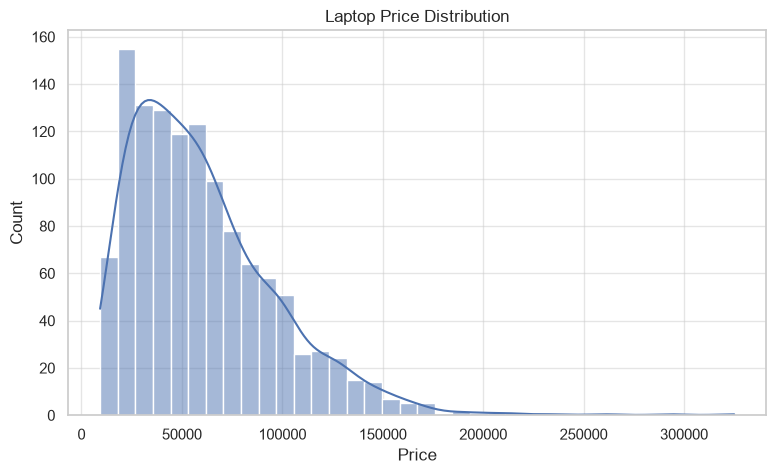

In [9]:
plt.figure(figsize=(9, 5))
sns.histplot(df['Price'], kde=True)
plt.title('Laptop Price Distribution')
plt.xlabel('Price')
plt.show()

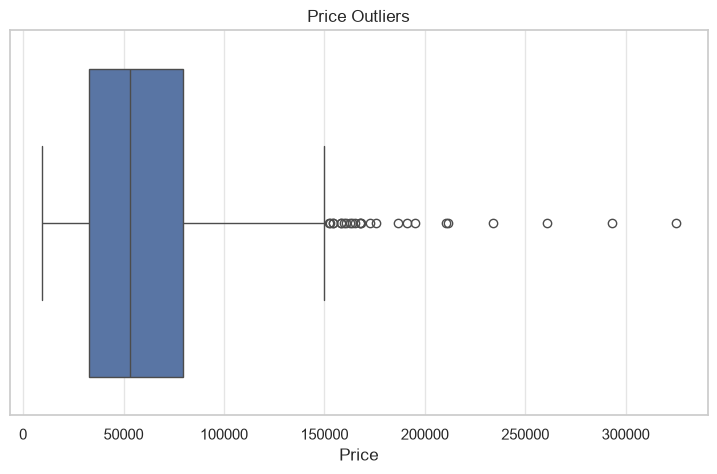

In [10]:
plt.figure(figsize=(9, 5))
sns.boxplot(x=df['Price'])
plt.title('Price Outliers')
plt.show()

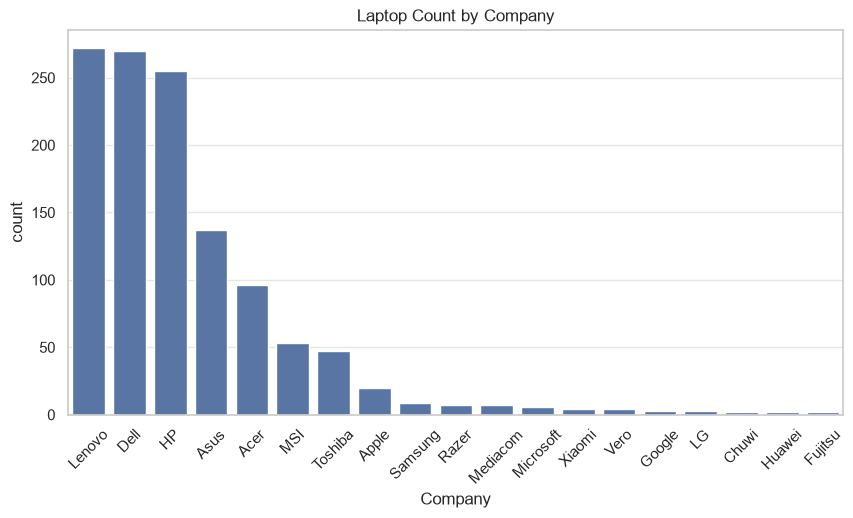

In [11]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Company', order=df['Company'].value_counts().index)
plt.xticks(rotation=45)
plt.title('Laptop Count by Company')
plt.show()

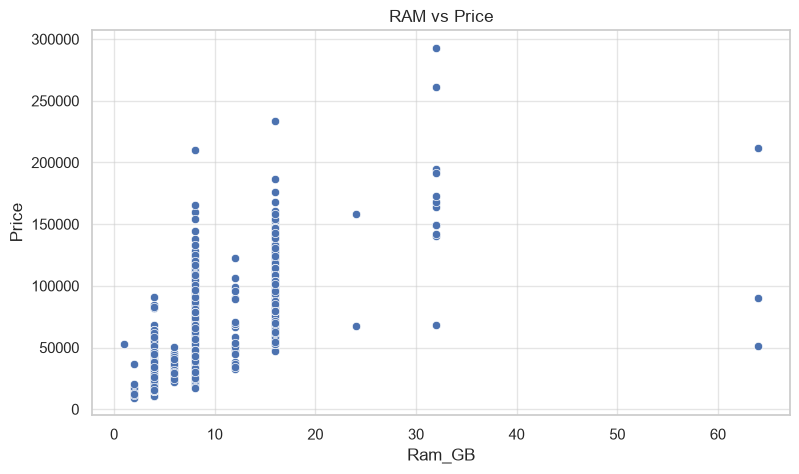

In [12]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x='Ram_GB', y='Price')
plt.title('RAM vs Price')
plt.show()

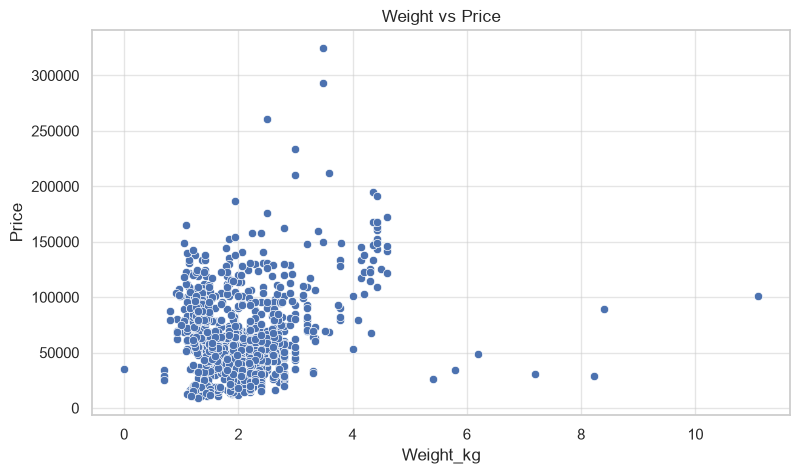

In [13]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x='Weight_kg', y='Price')
plt.title('Weight vs Price')
plt.show()

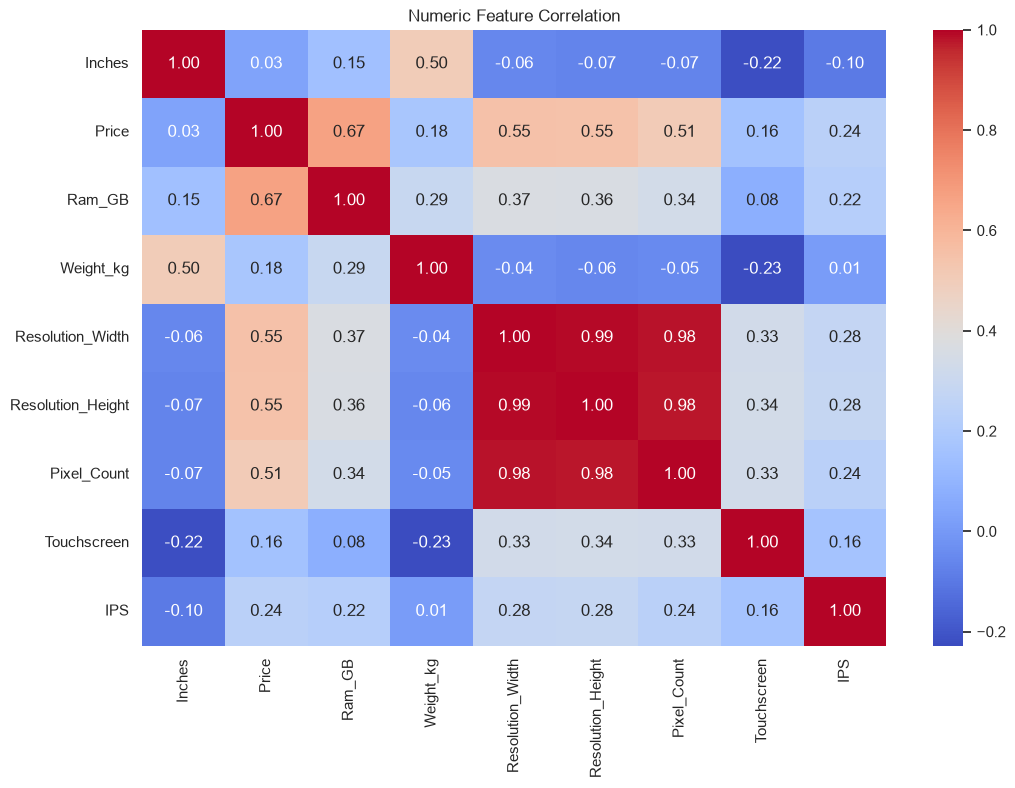

In [14]:
numeric_eda = df.select_dtypes(include=np.number)
plt.figure(figsize=(12, 8))
sns.heatmap(numeric_eda.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Numeric Feature Correlation')
plt.show()

In [15]:
target = 'Price'
drop_cols = ['Price', 'Ram', 'Weight']
X = df.drop(columns=[c for c in drop_cols if c in df.columns])
y = df[target]

X.shape, y.shape

((1206, 17), (1206,))

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train.shape, X_test.shape

((964, 17), (242, 17))

In [17]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

In [18]:
reg_models = {
    'Dummy': DummyRegressor(strategy='median'),
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(),
    'Lasso': Lasso(max_iter=10000),
    'ElasticNet': ElasticNet(max_iter=10000),
    'KNN': KNeighborsRegressor(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    'Extra Trees': ExtraTreesRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'AdaBoost': AdaBoostRegressor(random_state=42),
    'SVR': SVR()
}

In [19]:
reg_results = []

for name, model in reg_models.items():
    pipe = Pipeline([
        ('prep', preprocessor),
        ('model', model)
    ])
    cv_scores = cross_val_score(
        pipe, X_train, y_train, cv=5,
        scoring='neg_mean_absolute_error', n_jobs=1
    )
    reg_results.append({
        'Model': name,
        'CV_MAE': -cv_scores.mean(),
        'CV_STD': cv_scores.std()
    })

reg_results_df = pd.DataFrame(reg_results).sort_values('CV_MAE')
reg_results_df

,Model,CV_MAE,CV_STD
7,Random Forest,11991.597665,1074.158470
8,Extra Trees,12909.843698,1566.639938
9,Gradient Boosting,13150.552791,1123.528562
2,Ridge,13293.939155,1125.277795
5,KNN,13951.234385,1244.118078
3,Lasso,14533.794532,1198.309029
1,Linear Regression,14714.205057,1345.231374
6,Decision Tree,15485.980924,2065.768614
4,ElasticNet,18565.099269,1270.950012
10,AdaBoost,23613.530759,2068.936219


In [20]:
best_model_name = reg_results_df.iloc[0]['Model']
best_model = reg_models[best_model_name]

best_pipe = Pipeline([
    ('prep', preprocessor),
    ('model', best_model)
])

best_pipe.fit(X_train, y_train)
y_pred = best_pipe.predict(X_test)

test_metrics = pd.DataFrame([{
    'Model': best_model_name,
    'Test_MAE': mean_absolute_error(y_test, y_pred),
    'Test_RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
    'Test_R2': r2_score(y_test, y_pred)
}])
test_metrics

,Model,Test_MAE,Test_RMSE,Test_R2
0,Random Forest,11136.968546,19541.737086,0.702112


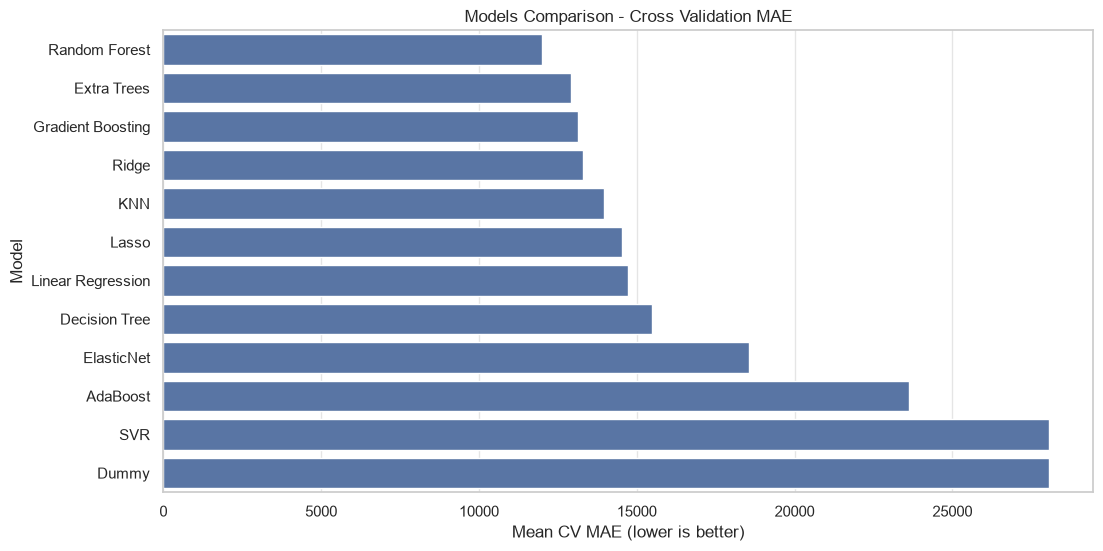

In [21]:
plt.figure(figsize=(12, 6))
sns.barplot(data=reg_results_df, x='CV_MAE', y='Model')
plt.title('Models Comparison - Cross Validation MAE')
plt.xlabel('Mean CV MAE (lower is better)')
plt.show()

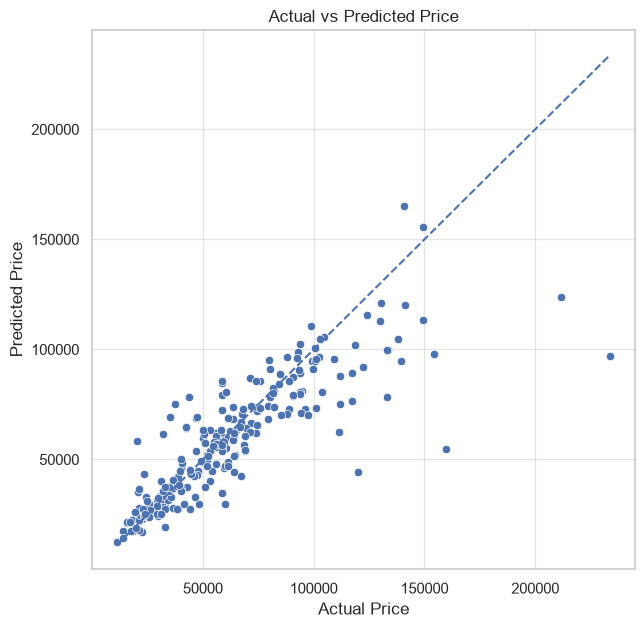

In [22]:
plt.figure(figsize=(7, 7))
sns.scatterplot(x=y_test, y=y_pred)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, '--')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Price')
plt.show()

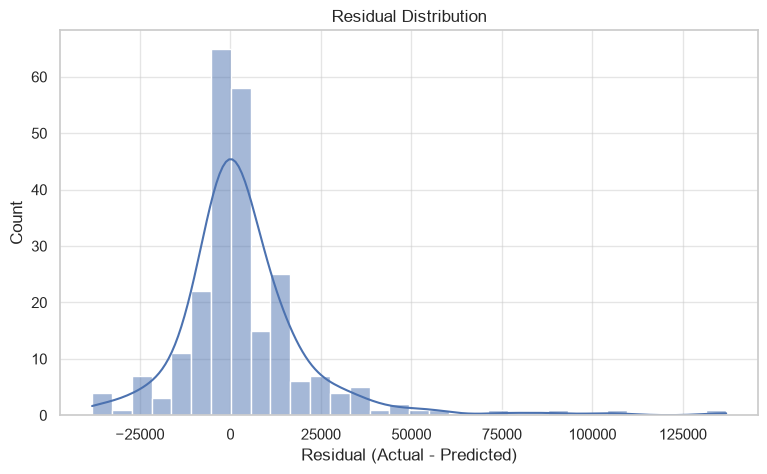

In [23]:
residuals = y_test - y_pred
plt.figure(figsize=(9, 5))
sns.histplot(residuals, kde=True)
plt.title('Residual Distribution')
plt.xlabel('Residual (Actual - Predicted)')
plt.show()

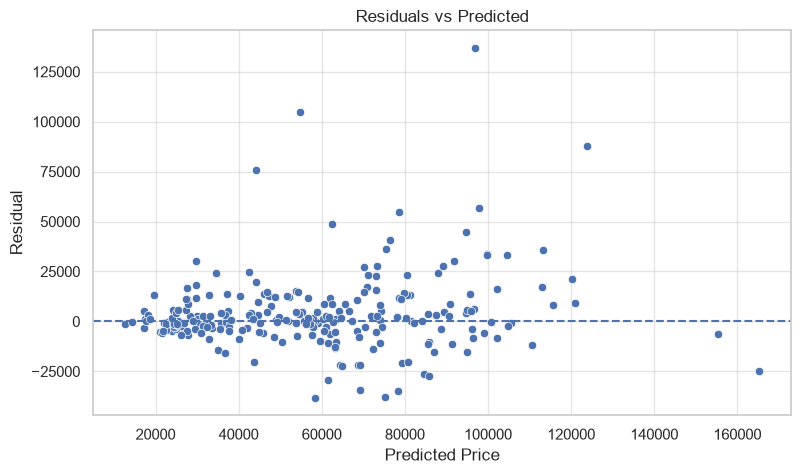

In [24]:
plt.figure(figsize=(9, 5))
sns.scatterplot(x=y_pred, y=residuals)
plt.axhline(0, linestyle='--')
plt.xlabel('Predicted Price')
plt.ylabel('Residual')
plt.title('Residuals vs Predicted')
plt.show()

In [25]:
print('Best model based on CV MAE:', best_model_name)
print('Test MAE:', round(mean_absolute_error(y_test, y_pred), 2))
print('Test RMSE:', round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print('Test R2:', round(r2_score(y_test, y_pred), 4))

Best model based on CV MAE: Random Forest
Test MAE: 11136.97
Test RMSE: 19541.74
Test R2: 0.7021
